<a href="https://colab.research.google.com/github/TejasDharmale/complex-adaptive-systems/blob/main/CAS_assignment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 5 - Controlled systems

    Name: Tejas Dharmale
    Student #: s1190137

In [1]:
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.random as jr

# Your RK4 function

In [2]:
def get_rk4(f, dt):
    def rk4_scan_fn(carry, t):
        k1 = f(carry, t)
        k2 = f(carry + dt*k1/2, t + dt/2)
        k3 = f(carry + dt*k2/2, t + dt/2)
        k4 = f(carry + dt*k3, t + dt)

        next_state = carry + dt*(k1 + 2*k2 + 2*k3 + k4)/6

        return next_state, next_state

    return rk4_scan_fn

# Exercise 1: Forced damped pendulum

## Exercise 1.1 (2 points)

Simulate the forced damped pendulum and show its position over time with $u(t) = a \sin(kt)$ with $a=1.5$ and $k=2/3$, and use $x_0 = [-\pi, 1.5 \pi]$. The equations of the damped pendulum are given by:

$$\dot{x}_1=x_2$$
$$\dot{x}_2=-\omega\sin(x_1) - \gamma x_2 + u(t),$$

with $\omega = 9.8$ and $\gamma = 0.5$.

## Solution 1.1

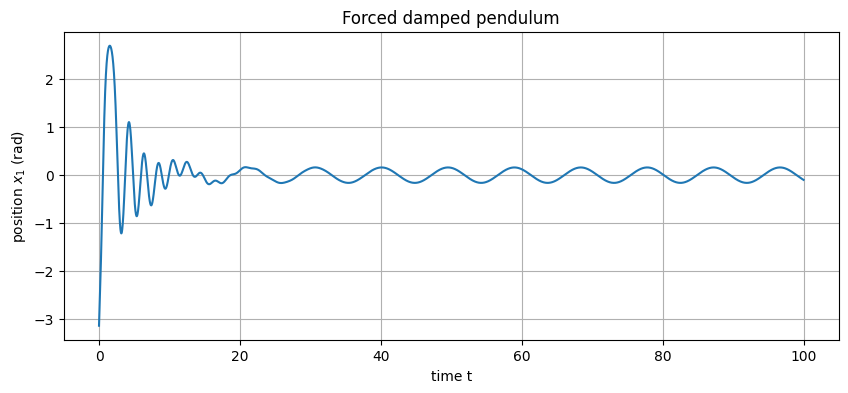

In [3]:
omega, gamma = 9.8, 0.5
a, k = 1.5, 2/3

def u(t):
    return a * jnp.sin(k * t)

def pendulum(x, t):
    return jnp.array([
        x[1],
        -omega * jnp.sin(x[0]) - gamma * x[1] + u(t)
    ])
dt = 0.01
T = 100.0
ts = jnp.arange(0, T, dt)
x0 = jnp.array([-jnp.pi, 1.5 * jnp.pi])
step = get_rk4(pendulum, dt)
_, xs = jax.lax.scan(step, x0, ts)

xs = jnp.concatenate([x0[None, :], xs])
times = jnp.arange(xs.shape[0]) * dt

plt.figure(figsize=(10, 4))
plt.plot(times, xs[:, 0])
plt.xlabel("time t")
plt.ylabel(r"position $x_1$ (rad)")
plt.title("Forced damped pendulum")
plt.grid(True)
plt.show()

In [4]:
# Transient: moves vertically up (-pi), swings down to ~2.7 rad without falling down, followed by damping oscillation at natural frequency (t ~ 2s) which fades out at t ~ 20.
# Steady state: small oscillation ~ 0.16 rad synchronized with forced period 2*pi/k ~ 9.4s, no resonance due to k << natural frequency.
# The long-term behavior of system depends on u(t) rather than x0 due to damping of initial condition.

## Exercise 1.2 (3 points)
Now simulate the forced damped pendulum with different control inputs (vary the driving frequency $k$). How does the time dependency of u(t) change the dynamics of the system?

Plot the cummulative cost of the trajectory with each control input, where the cost is the sum of the distance of the position from the origin and the quadratic control cost.

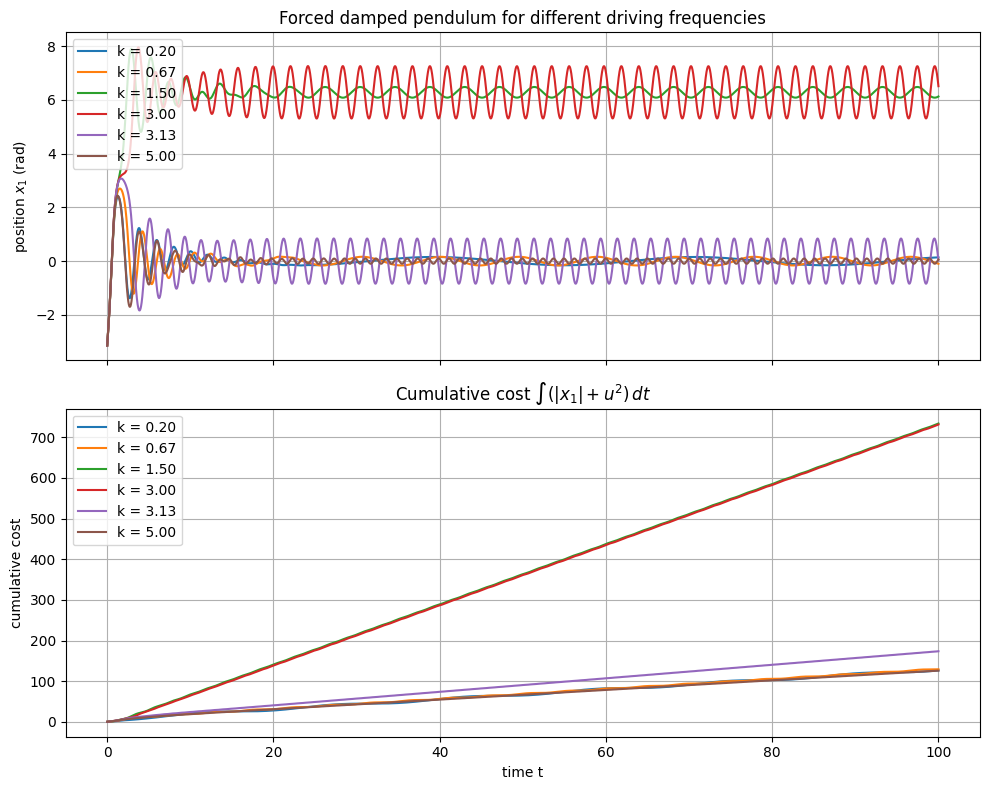

In [5]:
omega, gamma, a = 9.8, 0.5, 1.5
dt, T = 0.01, 100.0
ts = jnp.arange(0, T, dt)
x0 = jnp.array([-jnp.pi, 1.5 * jnp.pi])
ks = jnp.array([0.2, 2/3, 1.5, 3.0, jnp.sqrt(omega), 5.0])

def simulate(k):
    def f(x, t):
        u = a * jnp.sin(k * t)
        return jnp.array([x[1], -omega * jnp.sin(x[0]) - gamma * x[1] + u])
    _, xs = jax.lax.scan(get_rk4(f, dt), x0, ts)
    xs = jnp.concatenate([x0[None, :], xs])
    times = jnp.arange(xs.shape[0]) * dt
    us = a * jnp.sin(k * times)
    cost = jnp.cumsum((jnp.abs(xs[:, 0]) + us**2) * dt)
    return times, xs, us, cost
times, xs_all, us_all, cost_all = jax.vmap(simulate)(ks)
times = times[0]
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
for i, k in enumerate(ks):
    axes[0].plot(times, xs_all[i, :, 0], label=f"k = {k:.2f}")
    axes[1].plot(times, cost_all[i], label=f"k = {k:.2f}")
axes[0].set_ylabel(r"position $x_1$ (rad)")
axes[0].set_title("Forced damped pendulum for different driving frequencies")
axes[1].set_ylabel("cumulative cost")
axes[1].set_xlabel("time t")
axes[1].set_title(r"Cumulative cost $\int (|x_1| + u^2)\,dt$")
for ax in axes:
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# low k: the swing lags the slow driving force in small movements; driving frequency k well above sqrt(omega) is too fast to follow, making the response small as well.
# near the natural frequency k = sqrt(omega) ~ 3.13 there is a resonance effect, leading to big movements, maybe even rotating upside down, and large position penalty.
# the penalty of the controller u^2 averages to a^2/2 for all k, so the difference in total cost is caused almost exclusively by the position |x1|.

# Exercise 2: Controlled Lotka-Volterra

## Exercise 2.1 (2 points)
Create a stochastic Lotka-Volterra system that is solved using the Euler-Maruyama method (you can use your implementation of assignment 3, but you have to use Euler-Maruyama integration since it is a stochastic system). For the parameters, you can use:
$ \alpha = 1.1, \beta = 0.4, \delta = 0.1, \gamma =0.4$ with an initial condition of $\mathbf{x}_0 = (10,10)^\top$. For the Brownian motion, you can use $\sigma = 0.05$, multiplied with the state (this is called multiplicative noise). Make sure that your step size is small enough, and the duration of the system is sufficiently long for showing the long term evolution of the system.

## Solution 2.1

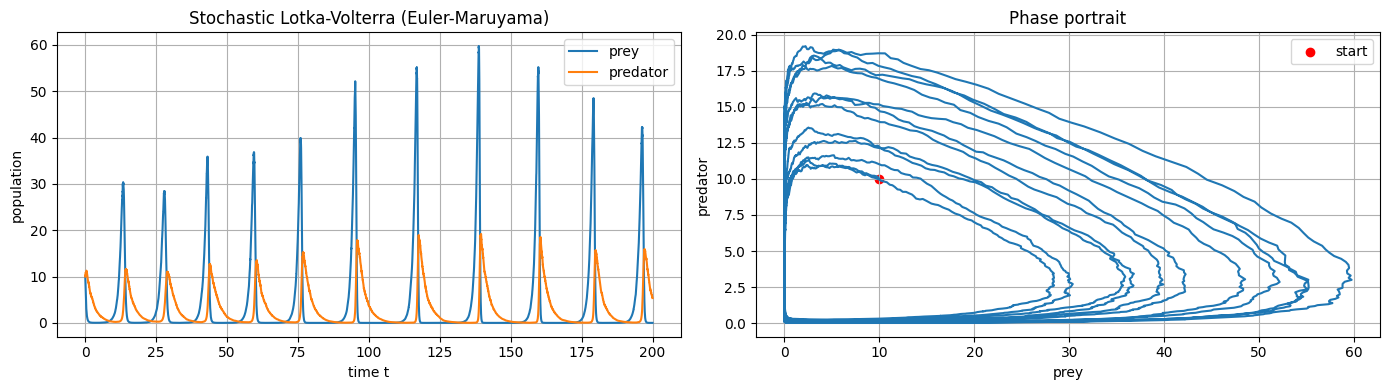

In [7]:
alpha, beta, delta, gamma_lv = 1.1, 0.4, 0.1, 0.4
sigma = 0.05
dt, T = 0.01, 200.0
ts = jnp.arange(0, T, dt)
x0 = jnp.array([10.0, 10.0])

def lv_drift(x, t):
    prey, pred = x
    return jnp.array([
        alpha * prey - beta * prey * pred,
        delta * prey * pred - gamma_lv * pred
    ])

def lv_diffusion(x, t):
    return sigma * x

def get_euler_maruyama(f, g, dt):
    def em_scan_fn(carry, inputs):
        t, dW = inputs
        next_state = carry + f(carry, t) * dt + g(carry, t) * dW
        return next_state, next_state
    return em_scan_fn
key = jr.PRNGKey(0)
dWs = jnp.sqrt(dt) * jr.normal(key, (len(ts), 2))
step = get_euler_maruyama(lv_drift, lv_diffusion, dt)
_, xs = jax.lax.scan(step, x0, (ts, dWs))
xs = jnp.concatenate([x0[None, :], xs])
times = jnp.arange(xs.shape[0]) * dt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(times, xs[:, 0], label="prey")
axes[0].plot(times, xs[:, 1], label="predator")
axes[0].set_xlabel("time t")
axes[0].set_ylabel("population")
axes[0].set_title("Stochastic Lotka-Volterra (Euler-Maruyama)")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(xs[:, 0], xs[:, 1])
axes[1].scatter(*x0, color="red", label="start")
axes[1].set_xlabel("prey")
axes[1].set_ylabel("predator")
axes[1].set_title("Phase portrait")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

In [8]:
# The prey and predators oscillations are out of phase, as in the deterministic case: the prey population peaks before the predators, and both oscillations decline.
# Due to multiplicative noise, the oscillations are not regular, i.e., the amplitude and period of oscillations are different each time and the trajectory does not close on itself.
# However, due to scaling of the noise with the system state, the oscillations will never decrease to zero, but over time they may either increase or decrease.

## Exercise 2.2 (3 points)
Create a control function $u(x)$ that receives the current state as input and returns an action as output. This control function has to be defined in such a way that the system becomes stabilized at the fixed point $\mathbf{x}^*_{\text{equilibrium}} = (\gamma / \delta , \alpha / \beta )^\top$. You are allowed to use this goal state in your definition of the control function.

For the result, show both the system evolution and control input over time, as well as the phase plane trajectory in a second figure.

Then, explain:

    - your reasoning behind the design of the control function;
    
    - discuss to what extent the system can be controlled to its equilibrium point;

## Solution 2.2

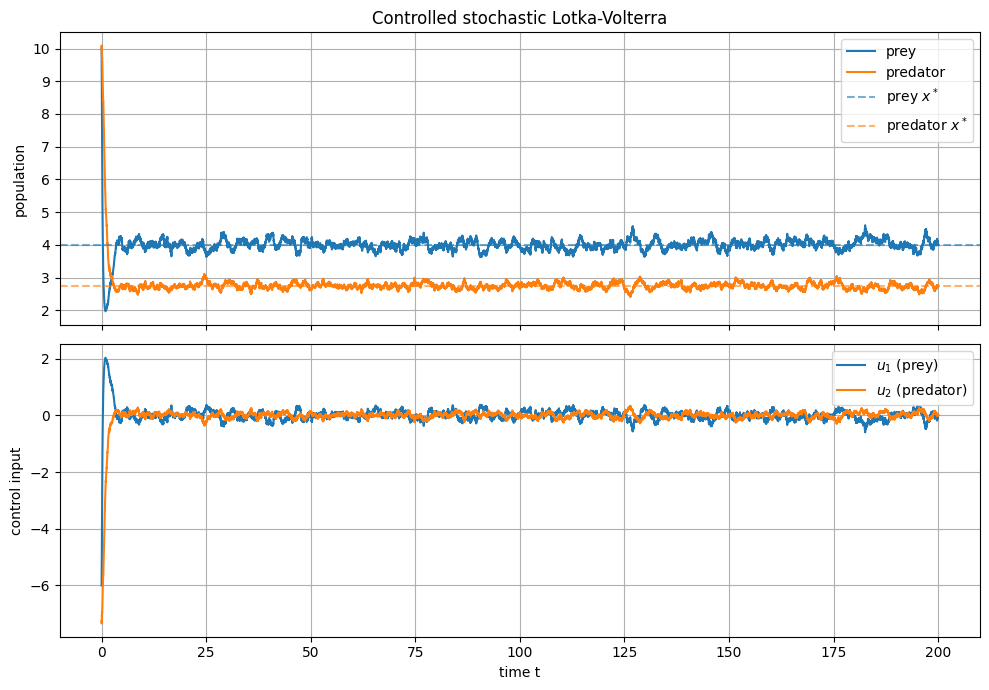

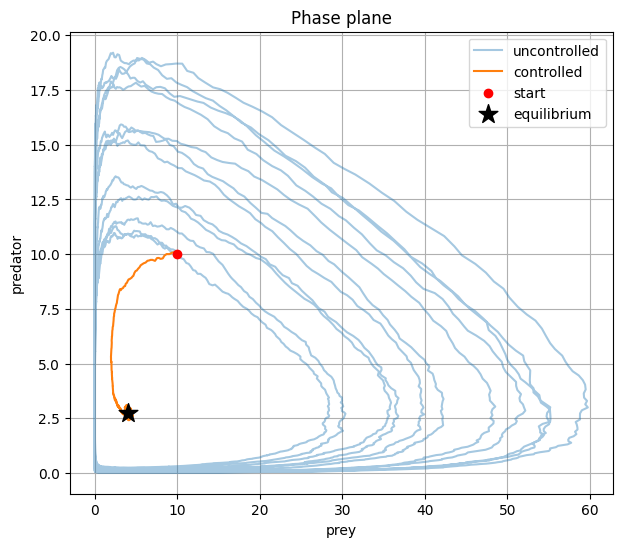

In [9]:
x_star = jnp.array([gamma_lv / delta, alpha / beta])  # (4.0, 2.75)
K = 1.0

def u(x):

    return -K * (x - x_star)

def lv_drift_controlled(x, t):
    return lv_drift(x, t) + u(x)

step_c = get_euler_maruyama(lv_drift_controlled, lv_diffusion, dt)
_, xs_c = jax.lax.scan(step_c, x0, (ts, dWs))
xs_c = jnp.concatenate([x0[None, :], xs_c])
us_c = jax.vmap(u)(xs_c)

# Figure 1
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(times, xs_c[:, 0], label="prey")
axes[0].plot(times, xs_c[:, 1], label="predator")
axes[0].axhline(x_star[0], color="C0", ls="--", alpha=0.6, label=r"prey $x^*$")
axes[0].axhline(x_star[1], color="C1", ls="--", alpha=0.6, label=r"predator $x^*$")
axes[0].set_ylabel("population")
axes[0].set_title("Controlled stochastic Lotka-Volterra")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(times, us_c[:, 0], label=r"$u_1$ (prey)")
axes[1].plot(times, us_c[:, 1], label=r"$u_2$ (predator)")
axes[1].set_xlabel("time t")
axes[1].set_ylabel("control input")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()
# Figure 2
plt.figure(figsize=(7, 6))
plt.plot(xs[:, 0], xs[:, 1], alpha=0.4, label="uncontrolled")
plt.plot(xs_c[:, 0], xs_c[:, 1], label="controlled")
plt.scatter(*x0, color="red", zorder=3, label="start")
plt.scatter(*x_star, color="black", marker="*", s=200, zorder=3, label="equilibrium")
plt.xlabel("prey")
plt.ylabel("predator")
plt.title("Phase plane")
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# With the proportional feedback u = -K(x - x*) the unstable point at x* becomes a stable spiral with convergence of the populations to (4, 2.75) in a couple of time units.
# The control term is initially large, approaching ~0 at x*, and thereafter compensating for the noise that keeps the state oscillating about x*.
# In the phase plane, the uncontrolled trajectories continue oscillating, whereas the controlled trajectory converges to the equilibrium.